# 01. Bài toán và dữ liệu (Bước 0 và 1)

**Nhiệm vụ của notebook này:** đặt bài toán và nhìn dữ liệu nói gì (mục 2.1, 2.2 của đề).

Chạy từng ô từ trên xuống. Notebook tự đọc `data.csv` (Colab sẽ hỏi bạn tải lên; trên máy thì đặt tại `data/data.csv`).

In [1]:
# Ô thiết lập: nạp thư viện và đọc dữ liệu
import io, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42                               # hạt giống ngẫu nhiên cố định: chạy lại ra đúng kết quả cũ
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def doc_du_lieu():
    """Tìm data.csv trên máy; nếu đang ở Colab thì xin người dùng tải lên."""
    for p in ["data/data.csv", "../data/data.csv", "data.csv"]:
        if os.path.exists(p):
            print("Đọc dữ liệu từ", p)
            return pd.read_csv(p, sep=";")
    try:
        from google.colab import files
        print("Hãy chọn tệp data.csv trên máy của bạn ...")
        up = files.upload()
        return pd.read_csv(io.BytesIO(list(up.values())[0]), sep=";")
    except ImportError:
        raise FileNotFoundError("Không thấy data.csv. Hãy đặt tệp vào thư mục data/.")


raw = doc_du_lieu()
raw.columns = [c.strip() for c in raw.columns]      # bỏ khoảng trắng/tab thừa ở tên cột
print("Kích thước:", raw.shape)

Đọc dữ liệu từ ../data/data.csv
Kích thước: (4424, 37)


---
# Bước 0. Bức tranh chung

**Vì sao cần bước này.** Nếu không biết mình đang đi đâu, mỗi công thức sẽ chỉ là một mảnh rời. Hãy giữ một sợi chỉ: *mỗi mảnh toán xuất hiện vì bài toán buộc phải có nó*.

| Câu hỏi đời thường | Mảnh toán xuất hiện | Bước |
|---|---|---|
| Em nào có nguy cơ bỏ học? Cần biết những gì để đoán? | Mô hình hóa bài toán, thống kê mô tả | 1 |
| Làm sao máy "hiểu" một sinh viên? | Vector, ma trận, tích vô hướng | 2 |
| Làm sao biến thông tin thành "khả năng bỏ học" và biết đoán sai đến đâu? | Sigmoid, xác suất, hàm mất mát | 3 |
| Làm sao sửa mô hình cho đoán đúng hơn? | Đạo hàm, gradient, Gradient Descent | 4 |
| Làm sao biết mô hình đoán đúng cả với sinh viên mới? | Chia dữ liệu, overfitting | 5 |
| Đoán tốt hay dở thì đo thế nào? | Precision, Recall, ngưỡng | 6 |
| Mô hình hiện đại (TabICLv2) làm điều đó ra sao? | Attention, học trong ngữ cảnh | 7 |

**Tự kiểm tra.** Hãy thử nói bằng ba câu: bài toán này là gì, em nào thuộc nhóm nguy cơ, và vì sao ta cần toán.

---
# Bước 1. Bài toán và dữ liệu (mục 2.1 và 2.2 của đề)

## Vì sao cần bước này
Muốn có bài toán thì phải nói rõ **thế nào là thành công, thế nào là thất bại**. Ở bài này: thành công là tốt nghiệp, thất bại là bỏ học. Ta quy ước:

- **Ô an toàn** là sinh viên *tốt nghiệp* (nhãn y = 0).
- **Nhóm nguy cơ** là sinh viên *bỏ học* (nhãn y = 1).
- **Ô chưa lật** là sinh viên *đang học*: chưa ai biết kết cục. Đưa họ vào thì mô hình sẽ học từ một nhãn chưa có kết luận, nên ta **loại họ khỏi bài toán**.

Vậy đây là bài toán **phân loại nhị phân**. Đầu ra của mô hình không chỉ là "bỏ học" hay "không", mà là một **xác suất** p = P(bỏ học | hồ sơ), để nhà trường tự chọn mức báo động.

## Làm gì và code
Ta (1) đếm các nhãn, (2) bỏ nhóm "đang học", (3) chỉ giữ tám chỉ số có lý do giáo dục rõ ràng, (4) xem dữ liệu nói gì.

In [2]:
# (1) và (2): đếm nhãn gốc, bỏ nhóm "Enrolled" (ô chưa lật), gán nhãn y
print(raw.Target.value_counts(), "\n")

d = raw[raw.Target != "Enrolled"].reset_index(drop=True)
d["y"] = (d.Target == "Dropout").astype(int)          # 1 = bỏ học (nguy cơ), 0 = tốt nghiệp (an toàn)
print(f"Còn {len(d)} sinh viên; tỉ lệ bỏ học = {d.y.mean():.1%}")
print(f"Nếu luôn đoán 'an toàn' thì vẫn đúng {1 - d.y.mean():.1%}, nhưng không phát hiện được em bỏ học nào")

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64 

Còn 3630 sinh viên; tỉ lệ bỏ học = 39.1%
Nếu luôn đoán 'an toàn' thì vẫn đúng 60.9%, nhưng không phát hiện được em bỏ học nào


,nhóm,số sinh viên,tỉ lệ trong dữ liệu,tỉ lệ bỏ học
0,Chưa đóng đủ học phí,486,13.4%,94.0%
1,Đã đóng đủ học phí,3144,86.6%,30.7%
2,Không nợ,3217,88.6%,34.5%
3,Đang nợ,413,11.4%,75.5%
4,Không học bổng,2661,73.3%,48.4%
5,Có học bổng,969,26.7%,13.8%


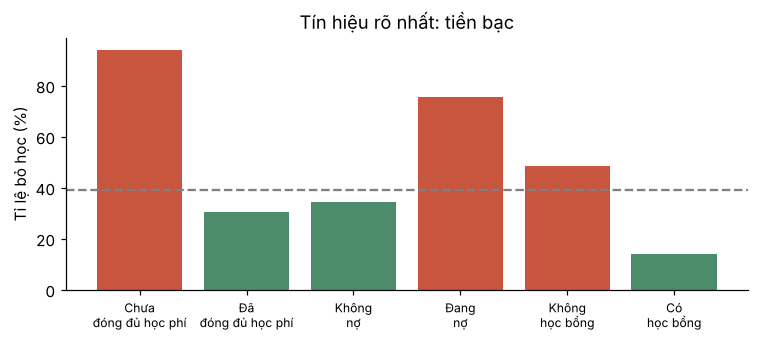

In [3]:
# (3): tám chỉ số của mỗi sinh viên
ENTRY = ["Tuition fees up to date", "Debtor", "Scholarship holder", "Age at enrollment"]
YEAR1 = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
         "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)"]
COMPACT = ENTRY + YEAR1                         # cấu hình chính (8 cột)
ADMISSION_ONLY = ["Admission grade", "Previous qualification (grade)", "Age at enrollment",
                  "Scholarship holder", "Debtor", "Tuition fees up to date", "Gender", "Application order"]
ALL = [c for c in d.columns if c not in ("Target", "y")]

# (4): dữ liệu nói gì? tỉ lệ bỏ học theo từng nhóm
rows = []
for cot, ten in [("Tuition fees up to date", {0: "Chưa đóng đủ học phí", 1: "Đã đóng đủ học phí"}),
                 ("Debtor", {0: "Không nợ", 1: "Đang nợ"}),
                 ("Scholarship holder", {0: "Không học bổng", 1: "Có học bổng"})]:
    for v, nhom in ten.items():
        m = d[cot] == v
        rows.append([nhom, int(m.sum()), m.mean(), d.loc[m, "y"].mean()])
bang = pd.DataFrame(rows, columns=["nhóm", "số sinh viên", "tỉ lệ trong dữ liệu", "tỉ lệ bỏ học"])
display(bang.style.format({"tỉ lệ trong dữ liệu": "{:.1%}", "tỉ lệ bỏ học": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(bang)), bang["tỉ lệ bỏ học"] * 100,
       color=["#C8553D", "#4C8C6B", "#4C8C6B", "#C8553D", "#C8553D", "#4C8C6B"])
ax.set_xticks(range(len(bang))); ax.set_xticklabels([n.replace(" ", "\n", 1) for n in bang["nhóm"]], fontsize=8)
ax.axhline(d.y.mean() * 100, ls="--", color="gray"); ax.set_ylabel("Tỉ lệ bỏ học (%)")
ax.set_title("Tín hiệu rõ nhất: tiền bạc"); plt.tight_layout(); plt.show()

In [4]:
# Thống kê mô tả cho biến định lượng (đề yêu cầu: trung bình, trung vị, phương sai, độ lệch chuẩn, phân vị)
quant = ["Age at enrollment"] + YEAR1
mo_ta = d[quant].describe(percentiles=[.25, .5, .75]).T
mo_ta["phương sai"] = d[quant].var()
display(mo_ta[["mean", "50%", "std", "phương sai", "min", "25%", "75%", "max"]].round(2))

# điểm 0 ở học kỳ 2: lỗi nhập liệu hay tín hiệu?
m0 = d["Curricular units 2nd sem (grade)"] == 0
print(f"\n{m0.sum()} sinh viên có điểm HK2 = 0; trong nhóm đó {d.loc[m0, 'y'].mean():.1%} đã bỏ học")

,mean,50%,std,phương sai,min,25%,75%,max
Age at enrollment,23.46,20.00,7.83,61.28,17.0,19.00,25.0,70.00
Curricular units 1st sem (approved),4.79,5.00,3.24,10.48,0.0,3.00,6.0,26.00
Curricular units 1st sem (grade),10.53,12.34,5.06,25.58,0.0,11.00,13.5,18.88
Curricular units 2nd sem (approved),4.52,5.00,3.16,10.00,0.0,2.00,6.0,20.00
Curricular units 2nd sem (grade),10.04,12.33,5.48,30.05,0.0,10.52,13.5,18.57



802 sinh viên có điểm HK2 = 0; trong nhóm đó 90.6% đã bỏ học


## Đọc kết quả
- **Tiền bạc là tín hiệu mạnh nhất.** Chưa đóng đủ học phí: khoảng 94% bỏ học, so với khoảng 31% ở nhóm đã đóng đủ. Đang nợ: khoảng 76% so với 34%. Có học bổng: khoảng 14% so với 48%.
- **Trung bình của điểm HK1 thấp hơn trung vị** (10,5 so với 12,3): có một nhóm điểm 0 kéo trung bình xuống.
- **Điểm 0 ở HK2 không phải lỗi.** Phần lớn (khoảng 91%) là những em đã bỏ học, vì em nghỉ rồi thì không còn điểm. Điều này kéo theo một **cảnh báo quan trọng**: dữ liệu học kỳ 2 phần nào *đã chứa sẵn đáp án*. Cảnh báo sớm thật sự phải dựa vào học kỳ 1 trở về trước. Ta sẽ gặp lại ở Bước 6.
- **Chỉ giữ tám cột.** Các cột như nghề nghiệp bố mẹ, GDP, lạm phát để ngoài. Không phải vì chắc chắn vô ích, mà vì câu hỏi gốc không cần chúng mới trả lời được. Đề bài cho phép nêu lý do không dùng một biến.

## Thầy có thể hỏi
- *Vì sao loại nhóm Enrolled?* Vì họ chưa có kết cục, giống ô chưa lật. Đưa vào thì mô hình học từ nhãn chưa có kết luận.
- *Dữ liệu lệch 39/61 có sao không?* Lệch nhưng chưa nặng. Cái cần cẩn thận là đừng chỉ nhìn Accuracy, vì đoán "ai cũng an toàn" đã đúng 61%. Ta sẽ nhìn Recall của lớp bỏ học.
- *Tương quan có phải nhân quả không?* Không. Nợ học phí đi cùng bỏ học, nhưng ta không khẳng định nợ gây ra bỏ học.